# Stationary instability (Pe = 4.5)

In [1]:
include("../src/stationary.jl")

# true: compute that data again and save it in data/stationary; false: load the saved data
# (spinodals and binodal: minutes; branches: about half an hour; time stepping: about an hour)
COMPUTE = (spinodals=false, binodal=false, branches=false, timestepping=false)

(spinodals = false, binodal = false, branches = false, timestepping = false)

## Spinodals

In [2]:
# Spinodals at Lx = 10 and Lx = 1000, with the criticality of the stationary bifurcation, and the binodal
spin10 = getdata(() -> spinodal_scan(PE_STAT, 10.0; n=500), "stationary/spinodal_Lx10.jld2", COMPUTE.spinodals)
spin1000 = getdata(() -> spinodal_scan(PE_STAT, 1000.0; n=10000), "stationary/spinodal_Lx1000.jld2", COMPUTE.spinodals)
binodal = getdata(() -> binodal_curve(PE_STAT), "stationary/binodal_Pe4.5.jld2", COMPUTE.binodal);

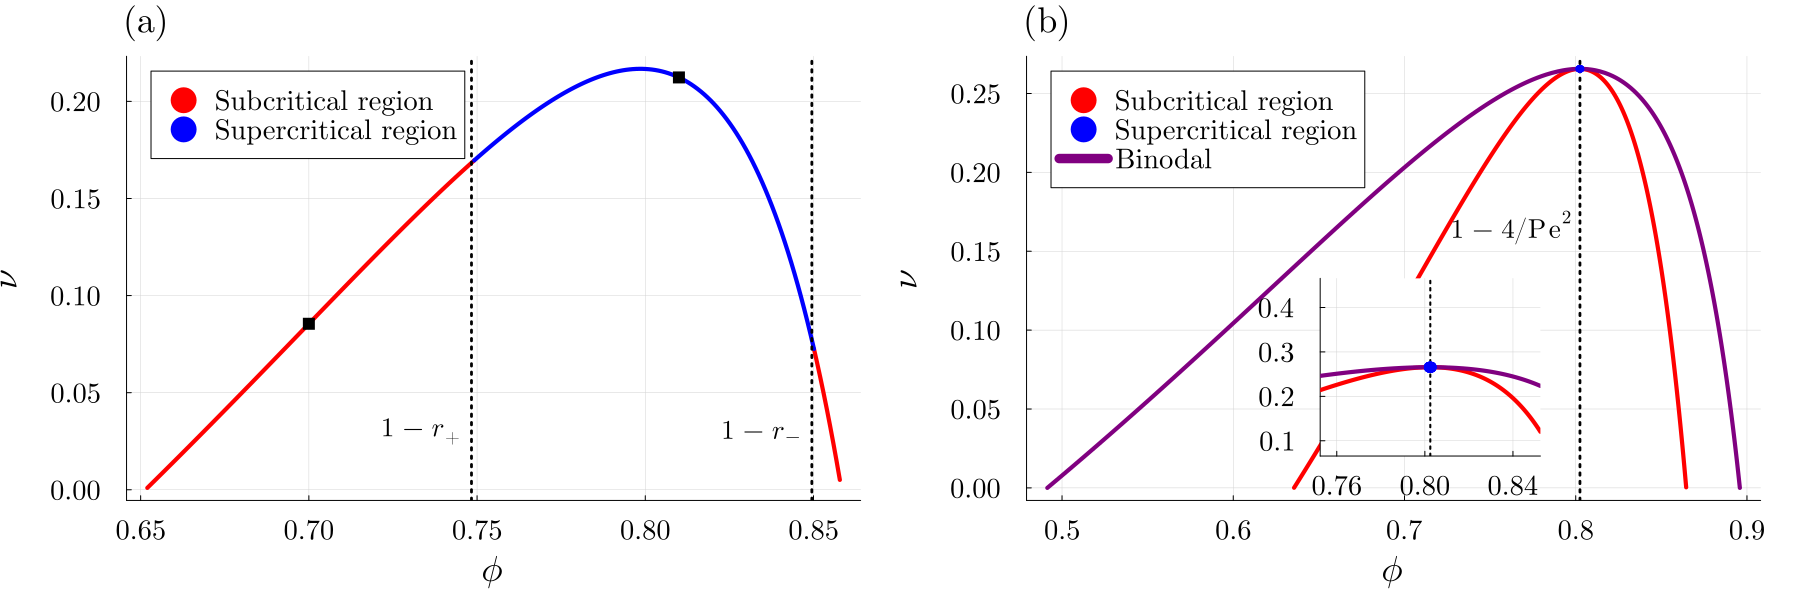

In [3]:
savepdf(spinodals_figure(spin10, spin1000, binodal), "stationary_spinodals")

## Supercritical bifurcation (φ = 0.81)

In [4]:
ϕ = 0.81
# Branches with 1, 2 and 3 wavelengths in the box (Newton on Nx = 2000 points; tolerance 1e-9, as round-off keeps the
# residual at 1e-10 to 3e-10 near the onset on this grid) with their weakly nonlinear amplitudes
b1 = getdata(() -> stationary_branch(ϕ, 1; Nx=2000, eps_max=0.115, tol=1e-9), "stationary/branch_phi0.81_n1.jld2", COMPUTE.branches)
b2 = getdata(() -> stationary_branch(ϕ, 2; Nx=2000, eps_max=0.085, eps_min=1e-3, min_step=1e-6, tol=1e-9), "stationary/branch_phi0.81_n2.jld2",
             COMPUTE.branches)
b3 = getdata(() -> stationary_branch(ϕ, 3; Nx=2000, eps_min=1e-3, min_step=1e-6, tol=1e-9), "stationary/branch_phi0.81_n3.jld2",
             COMPUTE.branches)
# Time stepping from random initial conditions at 10 values of φa, from the left end of the figure to φ
ts = getdata(() -> stationary_timestepping(ϕ, 0.745960296321839; T=10000.0), "stationary/timestepping_phi0.81.jld2", COMPUTE.timestepping);

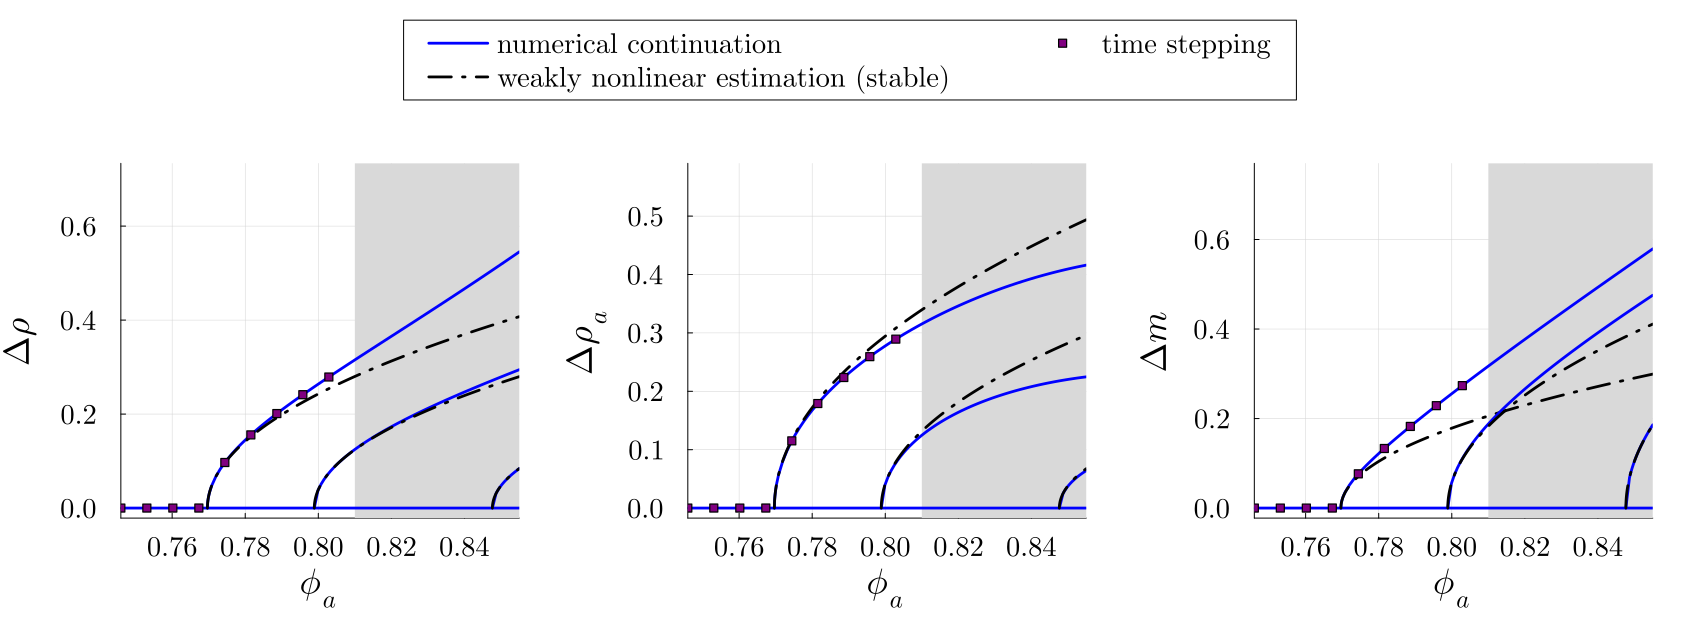

In [5]:
panels_081 = stationary_panels(ϕ, b1, b2, b3, ts; xlims=(0.745960296321839, 0.855))
fig = stationary_bifurcation_figure(panels_081)
savepdf(fig, "stationary_bifurcation_phi0.81")
fig

## Subcritical bifurcation (φ = 0.7)

In [6]:
ϕ = 0.7
qc, ϕac = find_qc_and_phiac(ϕ, PE_STAT, LX)
# Branch with 1 wavelength: unstable part from near onset to the fold, stable part around it; branches with 2 and 3
# wavelengths (Newton on Nx = 2000 points, tolerance 1e-9 as at φ = 0.81)
b1 = getdata(() -> subcritical_branch(ϕ; Nx=2000, tol=1e-9), "stationary/branch_phi0.7_n1.jld2", COMPUTE.branches)
b2 = getdata(() -> stationary_branch(ϕ, 2; Nx=2000, eps_max=0.085, eps_min=1e-3, min_step=1e-6, tol=1e-9), "stationary/branch_phi0.7_n2.jld2",
             COMPUTE.branches)
b3 = getdata(() -> stationary_branch(ϕ, 3; Nx=2000, eps_min=1e-3, min_step=1e-6, tol=1e-9), "stationary/branch_phi0.7_n3.jld2",
             COMPUTE.branches)
# Time stepping from random initial conditions at 10 values of φa from ϕac - 0.02 to φ
ts = getdata(() -> stationary_timestepping(ϕ, ϕac - 0.02; T=5000.0), "stationary/timestepping_phi0.7.jld2", COMPUTE.timestepping);

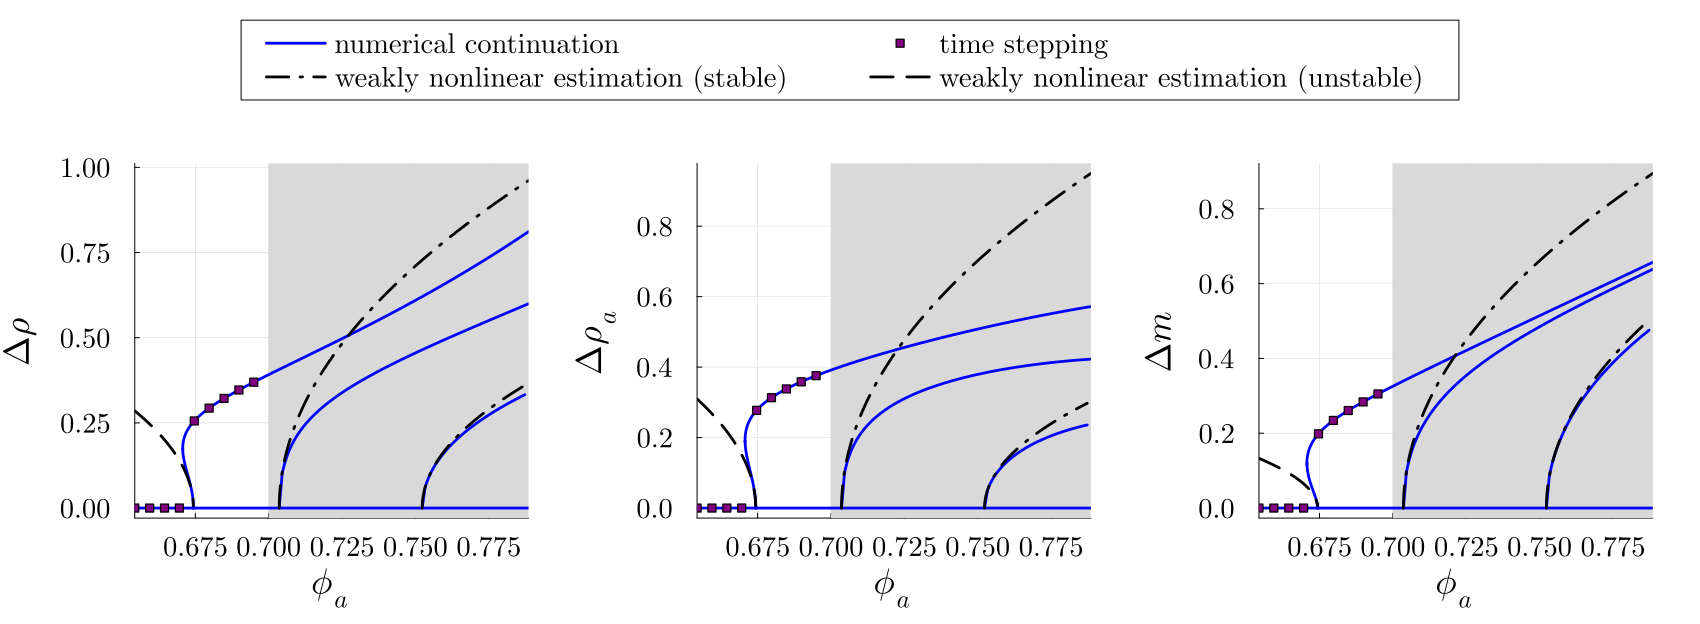

In [7]:
panels_07 = stationary_panels(ϕ, b1, b2, b3, ts; xlims=(ϕac - 0.02, b2.phia_wnl[end]))
fig = stationary_bifurcation_figure(panels_07)
savepdf(fig, "stationary_bifurcation_phi0.7")
fig

## Δρ at φ = 0.7 (a) and φ = 0.81 (b)

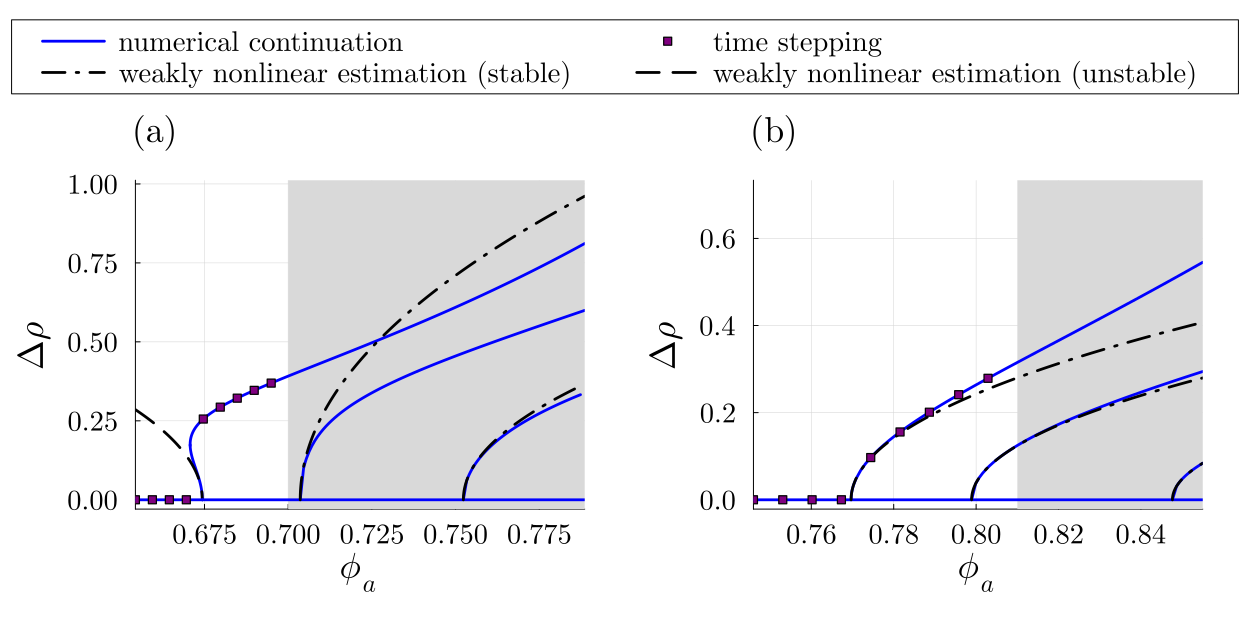

In [8]:
rho = stationary_rho_figure(panels_07[1], panels_081[1])
savepdf(rho, "stationary_bifurcation_rho")
rho